# Customer Churn Prediction (IBM Telco)

Goal: predict which customers will cancel their subscription, using demographics, account/usage and service-engagement features.

Steps: **1** setup, **2** EDA, **3** cleaning, **4** feature engineering, **5** ML pipeline, **6** model selection with cross-validation, **7** evaluation (ROC/AUC), **8** tuning and saving the model.

## Step 1: Setup

In [1]:
import os
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# Make the project root importable so we can use src/features.py
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
from src.features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, add_features, clean

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: Exploratory Data Analysis

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nBlank strings in TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Missing values per column:
Series([], dtype: int64)

Blank strings in TotalCharges: 11

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


About **26.5% of customers churn**, so the classes are imbalanced. Accuracy alone would be misleading (predicting "No" for everyone already scores 73%), so we use **ROC-AUC** and **recall on churners**.

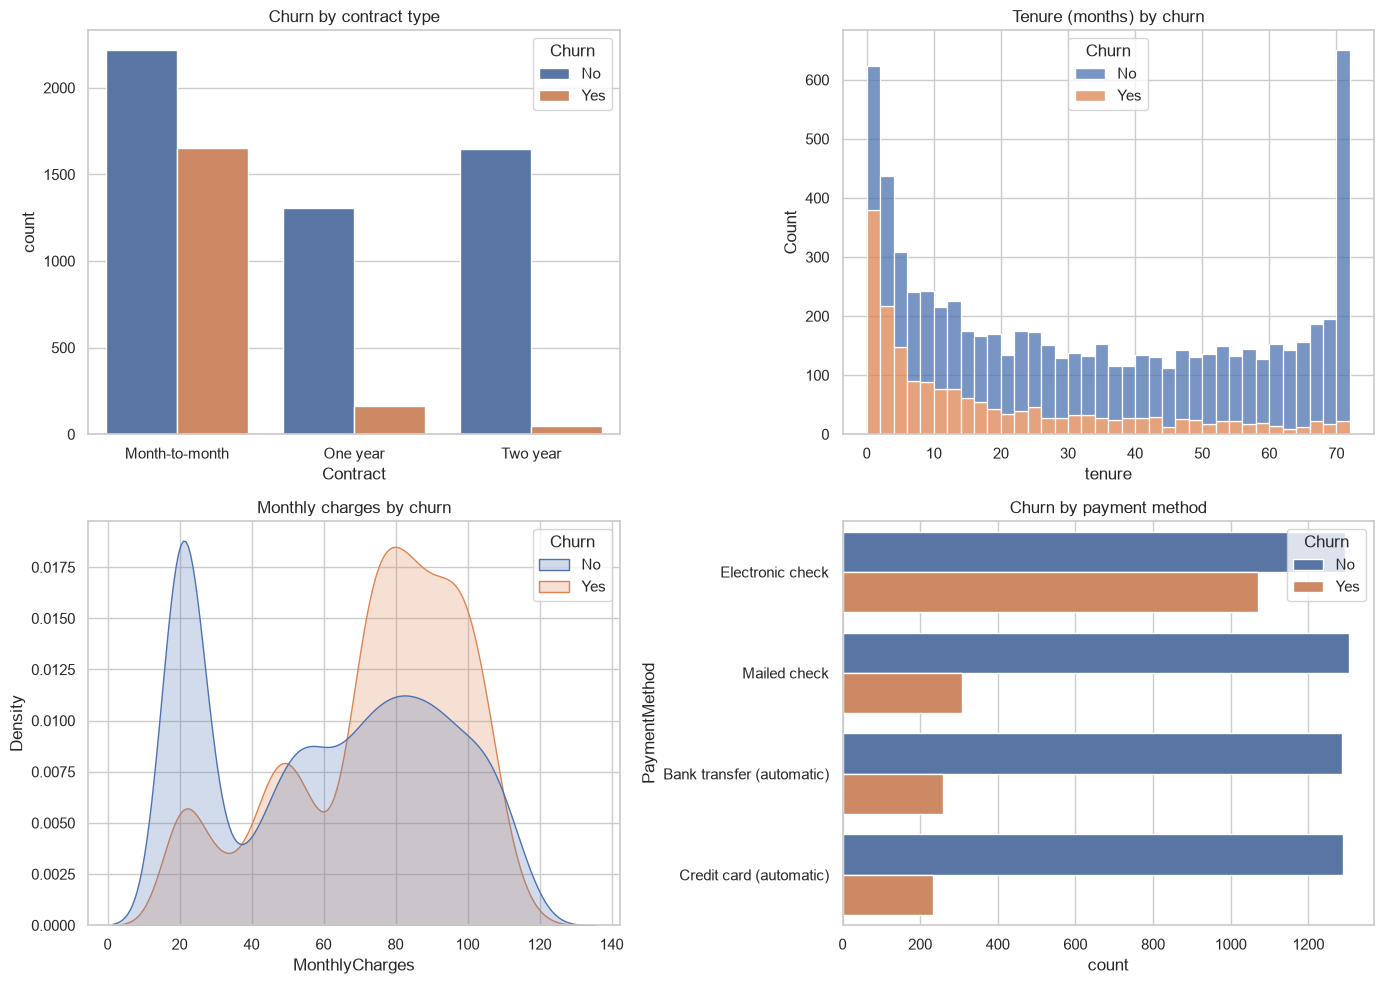

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn by contract type")

sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=axes[0, 1])
axes[0, 1].set_title("Tenure (months) by churn")

sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[1, 0])
axes[1, 0].set_title("Monthly charges by churn")

sns.countplot(data=df, y="PaymentMethod", hue="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Churn by payment method")

plt.tight_layout()
plt.show()

In [5]:
# Churn rate (%) for each category of a few key columns
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).round(1)
    print(f"{col}:\n{rate.sort_values(ascending=False)}\n")

Contract:
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

InternetService:
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64

PaymentMethod:
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64

TechSupport:
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64



**Observations**
- Month-to-month contracts churn far more than one or two year contracts.
- Churners are concentrated in the first months of tenure.
- Churners tend to have higher monthly charges.
- Electronic check users and fiber optic customers churn the most; customers without tech support churn more.

## Step 3: Data cleaning

In [6]:
# The 11 blank TotalCharges rows are all brand-new customers (tenure = 0)
print(df.loc[df["TotalCharges"].str.strip() == "", ["tenure", "MonthlyCharges", "TotalCharges"]])

df_clean = clean(df)  # TotalCharges -> numeric (blanks -> 0), drop customerID/Churn
print("\nTotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Remaining NaNs:", df_clean.isna().sum().sum())

# Features (raw columns) and binary target
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0})
print("X:", X.shape, " y positive rate:", round(y.mean(), 3))

      tenure  MonthlyCharges TotalCharges
488        0           52.55             
753        0           20.25             
936        0           80.85             
1082       0           25.75             
1340       0           56.05             
3331       0           19.85             
3826       0           25.35             
4380       0           20.00             
5218       0           19.70             
6670       0           73.35             
6754       0           61.90             

TotalCharges dtype: float64
Remaining NaNs: 0
X: (7043, 19)  y positive rate: 0.265


## Step 4: Feature engineering

Defined in `src/features.py` so the saved model can reuse it:
- `tenure_group`: tenure bucketed into 0-12, 13-24, 25-48, 49+ months
- `avg_monthly_spend`: TotalCharges / tenure (falls back to MonthlyCharges for new customers)
- `num_services`: count of subscribed services (phone, internet and add-ons)

In [7]:
df_feat = add_features(df)
df_feat[["tenure", "tenure_group", "TotalCharges", "avg_monthly_spend", "num_services"]].head()

,tenure,tenure_group,TotalCharges,avg_monthly_spend,num_services
0,1,0-12,29.85,29.850000,2
1,34,25-48,1889.50,55.573529,4
2,2,0-12,108.15,54.075000,4
3,45,25-48,1840.75,40.905556,4
4,2,0-12,151.65,75.825000,2


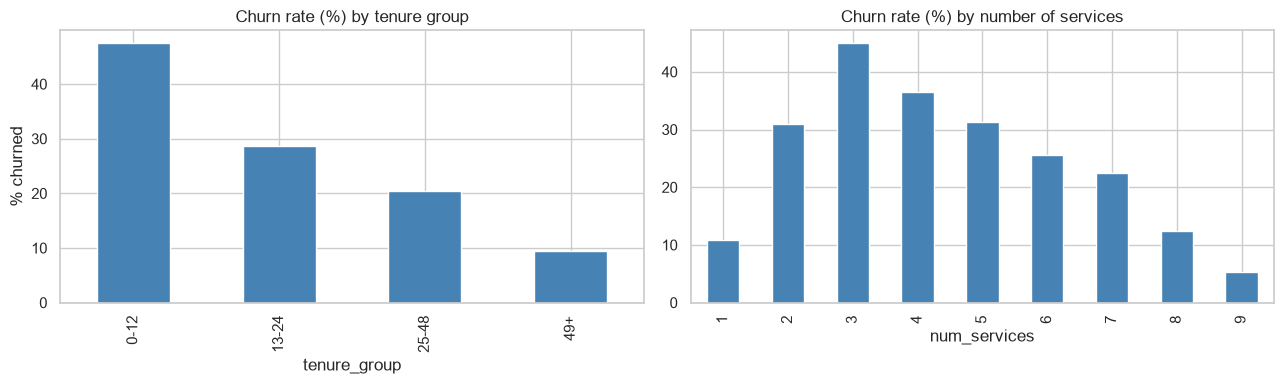

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(df_feat.assign(Churn=y).groupby("tenure_group")["Churn"].mean() * 100).reindex(
    ["0-12", "13-24", "25-48", "49+"]).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Churn rate (%) by tenure group")
axes[0].set_ylabel("% churned")

(df_feat.assign(Churn=y).groupby("num_services")["Churn"].mean() * 100).plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Churn rate (%) by number of services")
plt.tight_layout()
plt.show()

## Step 5: ML pipeline

One `Pipeline` does everything: feature engineering, then scaling of numeric columns and one-hot encoding of categorical columns, then the model. Because every step is fitted inside the pipeline, cross-validation has no data leakage, and the saved model accepts raw rows.

In [9]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])

def make_pipeline(model):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", preprocessor),
        ("model", model),
    ])

# Stratified split keeps the 26.5% churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "churn rate", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "churn rate", round(y_test.mean(), 3))

Train: (5634, 19) churn rate 0.265
Test:  (1409, 19) churn rate 0.265


## Step 6: Model selection with cross-validation

5-fold `StratifiedKFold` on the training set only, scored by ROC-AUC. All models are balanced for the class imbalance: Logistic Regression and Random Forest use `class_weight="balanced"`. GradientBoostingClassifier has no `class_weight` option, so it gets the equivalent balanced `sample_weight` when it is fitted.

In [10]:
def fit_params(name, y_fit):
    """Balanced sample weights for GradientBoosting (other models use class_weight)."""
    if name == "GradientBoosting":
        return {"model__sample_weight": compute_sample_weight("balanced", y_fit)}
    return {}


models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc",
                             params=fit_params(name, y_train), n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:20s} ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

best_name = max(cv_scores, key=lambda n: cv_scores[n].mean())
print("\nBest model by CV ROC-AUC:", best_name)

LogisticRegression   ROC-AUC = 0.8457 +/- 0.0112


RandomForest         ROC-AUC = 0.8447 +/- 0.0089


GradientBoosting     ROC-AUC = 0.8466 +/- 0.0118

Best model by CV ROC-AUC: GradientBoosting


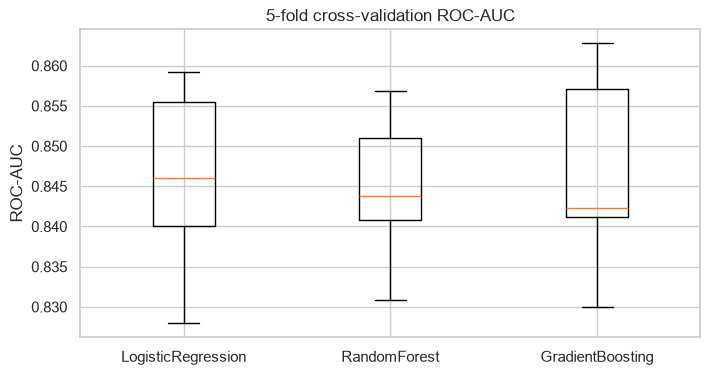

In [11]:
plt.figure(figsize=(8, 4))
plt.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
plt.ylabel("ROC-AUC")
plt.title("5-fold cross-validation ROC-AUC")
plt.show()

## Step 7: Evaluation on the test set

Fit the best model on the full training set, then evaluate it once on the held-out test set.

In [12]:
best_pipe = make_pipeline(models[best_name]).fit(X_train, y_train, **fit_params(best_name, y_train))
y_pred = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC ({best_name}): {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Stay (0)", "Churn (1)"]))

Test ROC-AUC (GradientBoosting): 0.8412

              precision    recall  f1-score   support

    Stay (0)       0.91      0.73      0.81      1035
   Churn (1)       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.81      0.75      0.76      1409



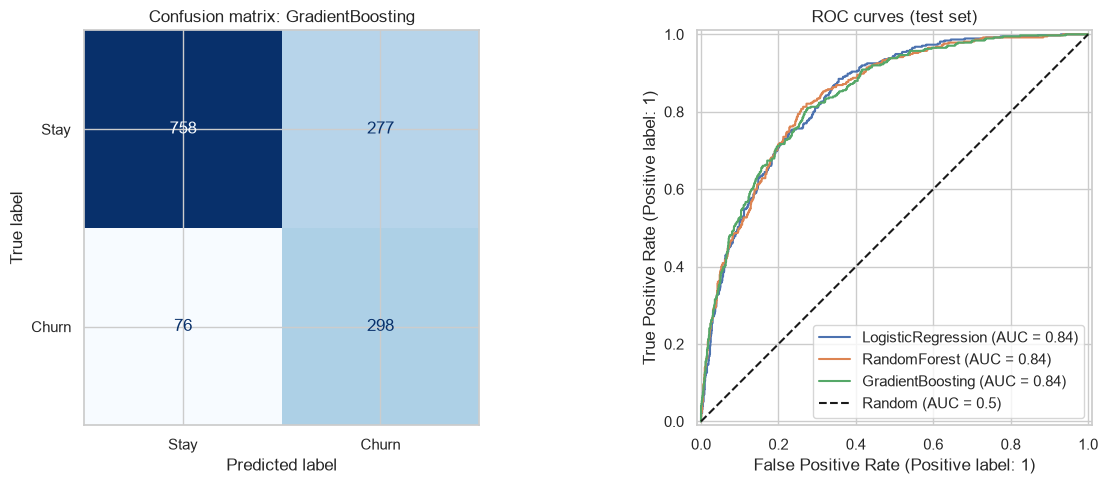

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stay", "Churn"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_name}")

# ROC curves of all three models on the test set
for name, model in models.items():
    pipe = best_pipe if name == best_name else make_pipeline(model).fit(
        X_train, y_train, **fit_params(name, y_train))
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
axes[1].legend(loc="lower right")
axes[1].set_title("ROC curves (test set)")
plt.tight_layout()
plt.show()

**Recall for churners** is the key business metric: it is the share of customers who actually churn that the model catches, so the retention team can contact them in time. Class balancing trades some precision for much higher recall (without it, this kind of model catches only about half of the churners).

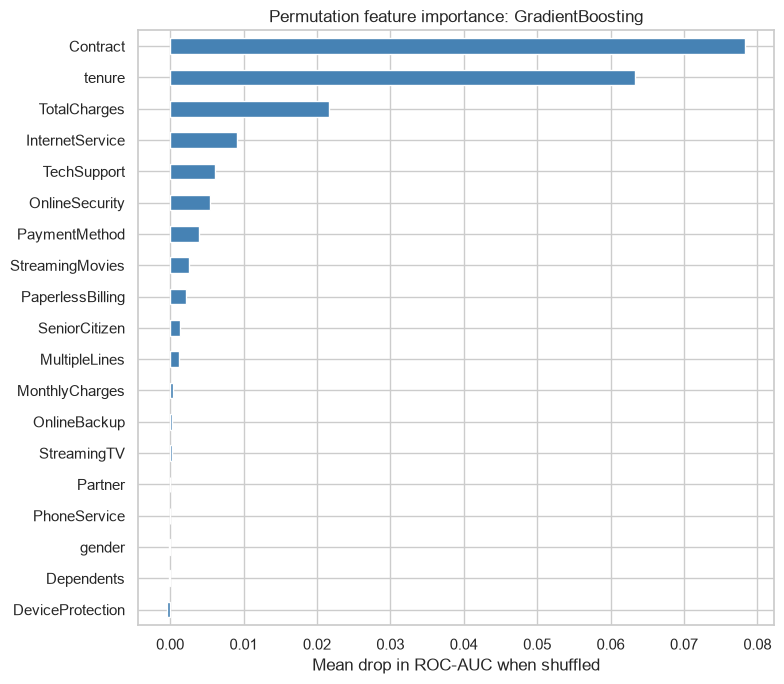

In [14]:
# Feature importance: permutation importance on the original input columns
# (how much test ROC-AUC drops when a column is shuffled)
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot.barh(color="steelblue")
plt.xlabel("Mean drop in ROC-AUC when shuffled")
plt.title(f"Permutation feature importance: {best_name}")
plt.tight_layout()
plt.show()

## Step 8: Hyperparameter tuning and saving the model

In [15]:
param_grids = {
    "LogisticRegression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "RandomForest": {"model__n_estimators": [200, 400],
                     "model__max_depth": [None, 8, 12],
                     "model__min_samples_leaf": [1, 5, 10]},
    "GradientBoosting": {"model__n_estimators": [100, 200, 300],
                         "model__learning_rate": [0.03, 0.05, 0.1],
                         "model__max_depth": [2, 3]},
}

grid = GridSearchCV(make_pipeline(models[best_name]), param_grids[best_name],
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train, **fit_params(best_name, y_train))

print("Best params:", grid.best_params_)
print(f"Best CV ROC-AUC: {grid.best_score_:.4f}")

final_model = grid.best_estimator_
final_proba = final_model.predict_proba(X_test)[:, 1]
print(f"Tuned test ROC-AUC: {roc_auc_score(y_test, final_proba):.4f}\n")
print(classification_report(y_test, final_model.predict(X_test), target_names=["Stay (0)", "Churn (1)"]))

Best params: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300}
Best CV ROC-AUC: 0.8494
Tuned test ROC-AUC: 0.8449

              precision    recall  f1-score   support

    Stay (0)       0.91      0.72      0.80      1035
   Churn (1)       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [16]:
os.makedirs("../models", exist_ok=True)
joblib.dump(final_model, "../models/churn_model.pkl")
print("Saved model to models/churn_model.pkl")

# Sanity check: reload and predict on 5 raw customers
reloaded = joblib.load("../models/churn_model.pkl")
sample = df.sample(5, random_state=RANDOM_STATE)
pd.DataFrame({
    "customerID": sample["customerID"],
    "actual_churn": sample["Churn"],
    "churn_probability": reloaded.predict_proba(sample)[:, 1].round(3),
})

Saved model to models/churn_model.pkl


,customerID,actual_churn,churn_probability
185,1024-GUALD,Yes,0.853
2715,0484-JPBRU,No,0.229
3825,3620-EHIMZ,No,0.046
1807,6910-HADCM,Yes,0.871
132,8587-XYZSF,No,0.078


## Summary
- Data: 7,043 customers, 26.5% churn (imbalanced).
- Cleaning: `TotalCharges` converted to numeric (11 blanks for new customers set to 0), `customerID` dropped, `Churn` mapped to 1/0.
- Features: tenure group, average monthly spend, number of services, plus one-hot encoded categoricals and scaled numerics.
- Three models compared with stratified 5-fold CV on ROC-AUC; the best was tuned with GridSearchCV and saved to `models/churn_model.pkl`.
- Strongest churn drivers: tenure, contract type and internet service type, followed by tech support and online security.
- Use `python src/predict.py <csv>` to score new customers.